# 8 The Vicsek model

## The effect of delay

<div style="background-color: #f0f8ff; border: 2px solid #4682b4; padding: 10px;">
<strong>Note:</strong> This notebook contains the code for section 8.2 from the book  

**Simulation of Complex Systems**  
Aykut Argun, Agnese Callegari, and Giovanni Volpe<br>
IOP Publishing, Bristol, UK, 2021<br>
ISBN: 978-0-7503-3843-1<br>
[https://iopscience.iop.org/book/mono/978-0-7503-3843-1](https://iopscience.iop.org/book/mono/978-0-7503-3843-1)

You can find the other notebooks on the [Simulation of Complex Systems GitHub page](../../)
</div>

**Reference:** Piwowarczyk *et al.* (2019) [*Influence of sensorial delay on clustering and swarming*](https://doi.org/10.1103/PhysRevE.100.012607).

<a id="positive-delay"></a>
**Positive delay** in updating the orientation.

Equation (8.7):

$$\theta_{j,\,n+1}=\langle \theta_{j,\,n-h} \rangle +\eta\, W_{j,\,n}\Delta t$$ 


$h$ is the delay (number of time steps)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import sys
sys.path.insert(0, '../08_modules')

import vicsek_model as vm
import vm_visualize as vis

pygame 2.5.2 (SDL 2.28.3, Python 3.8.5)
Hello from the pygame community. https://www.pygame.org/contribute.html


Let's set the simulation parameters:

In [2]:
n_part = 50
box_length = 100.0
speed = 0.03
dt = 1.0 
noise = 0.4
flocking_radius = 20.0

h = 2  # delay

rng = np.random.default_rng()


Let's initialize the `history`, list of past orientations for all particles.

In [3]:
theta = rng.uniform(-np.pi, np.pi, n_part)

history = [theta.copy() for _ in range(h + 1)]

print(f'len(history) : {len(history)}')

print('Time indices, oldest to newest:', list(range(-h, 1)))

print('Current heading of particle 0: '
      f'{history[-1][0]:.3f}')
print('Delayed heading of particle 0: '
      f'{history[-h-1][0]:.3f}')

len(history) : 3
Time indices, oldest to newest: [-2, -1, 0]
Current heading of particle 0: 2.746
Delayed heading of particle 0: 2.746


The initial *transient* is set. 

We will not compare statistics until after that transient.

Let's see how the delay affects the reorientation of a single particle.

In [4]:
pos = rng.uniform(0, box_length, (n_part, 2))

j = 0  # chosen reference particle

members = []
for k in range(n_part):
    displacement = pos[k] - pos[j]
    displacement -= box_length * np.rint(displacement / box_length)
    if np.dot(displacement, displacement) < flocking_radius**2:
        members.append(k)
perceived = history[-h - 1][members]
print(f'Neighbor indices: {members}')
print(f'perceived orientations: {perceived.round(2)}')

Neighbor indices: [0, 15, 19, 32, 46]
perceived orientations: [ 2.75 -2.42 -2.62 -2.45 -0.  ]


Let's implement a small simulation with delay:

In [5]:
n_part = 20
box_length = 100.0
speed = 3.0
dt = 1.0
flocking_radius = 5.0 
noise = 0.4
h = 2

dt = 1.0
n_steps = 12

rng = np.random.default_rng()

# initialization
pos, theta = vm.initial_state(n_part, box_length)

history = [theta.copy() for _ in range(h + 1)]

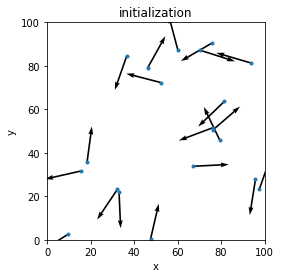

In [6]:
vel = speed * np.column_stack((np.cos(theta), np.sin(theta)))
fig, ax = vis.plot_particles(
    pos, vel, box_length, step=0
)
plt.title('initialization')
plt.show()


In [7]:
for step in range(n_steps):
    next_theta = np.empty_like(theta)
    members = vm.metric_neighbors(
        pos, box_length, flocking_radius
    )
    for j in range(n_part):
        past_theta = history[-h - 1][members[j]]
        next_theta[j] = vm.circular_mean(past_theta)
        next_theta[j] += noise * rng.uniform(-0.5, 0.5)
    pos += speed * np.column_stack((np.cos(theta), np.sin(theta)))
    pos %= box_length
    theta = next_theta
    history.append(theta.copy())
    history.pop(0)

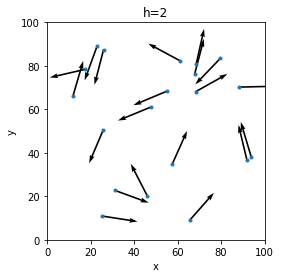

In [8]:
vel = speed * np.column_stack((np.cos(theta), np.sin(theta)))
fig, ax = vis.plot_particles(
    pos, vel, box_length, step=step
)
plt.title('h=2')
plt.show()


<a id="effect-positive-delay"></a>
Let's see the effect of no delay, short delay, long delay.

We follow the protocol explained above (history list of positions, orientation chosen on the base of the current neighbours, but with their past orientation of $h$ time step before).

In [9]:
n_part = 100
box_length = 1000.0
speed = 3.0
flocking_radius = 20.0 
noise = 0.4

dt = 1.0

rng = np.random.default_rng()

start_pos, start_theta = vm.initial_state(n_part, box_length)
comparison_delays = [0, 2, 25]
n_steps = 2000  # Then increase to >5000 
n_skip = 20
results = {}

In [10]:
for delay in comparison_delays:
    p = start_pos.copy()
    a = start_theta.copy()
    history = [a.copy() for _ in range(delay + 1)]
    psi_series = [vm.alignment(a)]
    c, _ = vm.voronoi_clustering(p, box_length, flocking_radius)
    c_series = [c]
    for step in range(1, n_steps + 1):
        p, a = vm.step_delayed(
            p, a, history, delay, box_length,
            speed, flocking_radius, noise, dt)
        history.append(a.copy())
        history.pop(0)
        if step % n_skip == 0:
            psi_series.append(vm.alignment(a))
            c, _ = vm.voronoi_clustering(
                p, box_length, flocking_radius)
            c_series.append(c)
    results[delay] = (p, a, psi_series, c_series)

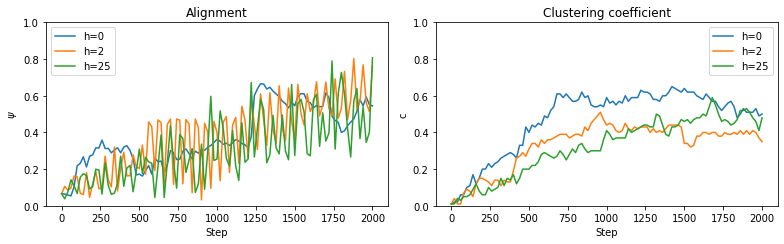

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for delay in comparison_delays:
    p, a, psi, c = results[delay]
    axes[0].plot(np.arange(len(psi)) * n_skip, psi, 
                 label=f'h={delay}')
    axes[1].plot(np.arange(len(c)) * n_skip, c, 
                 label=f'h={delay}')
axes[0].set(
    title='Alignment', 
    xlabel='Step', 
    ylabel=r'$\psi$', 
    ylim=(0, 1)
)
axes[1].set(
    title='Clustering coefficient', 
    xlabel='Step', 
    ylabel='c', 
    ylim=(0, 1)
)
for ax in axes: ax.legend()
plt.tight_layout(); plt.show()

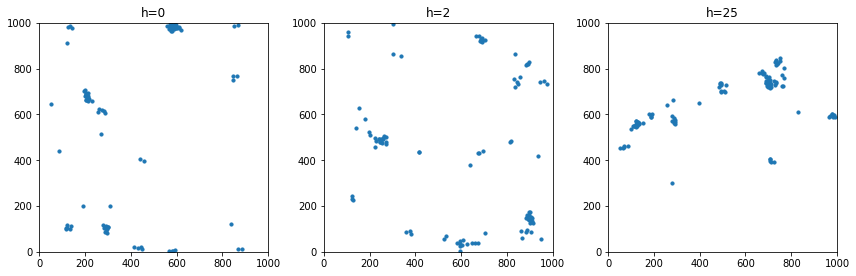

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, delay in zip(axes, comparison_delays):
    pos_final = results[delay][0]
    ax.scatter(
        pos_final[:, 0], 
        pos_final[:, 1], 
        s=10
    )
    ax.set(
        xlim=(0, box_length), 
        ylim=(0, box_length), 
        title=f'h={delay}'
    )
    ax.set_aspect('equal')
plt.tight_layout()
plt.show()

<a id="effect-positive-delay"></a>
Let's see the effect of no delay, short delay, long delay.

This time, we use a **different protocol**: both neighbours and angles are $h$ steps in the past.

In [13]:
n_part = 100
box_length = 1000.0
speed = 3.0
flocking_radius = 20.0 
noise = 0.4

dt = 1.0

rng = np.random.default_rng()

start_pos, start_theta = vm.initial_state(n_part, box_length)
comparison_delays = [0, 2, 25]
n_steps = 2000  # Then increase to >5000 
n_skip = 20
results = {}

In [14]:
for delay in comparison_delays:

    p = start_pos.copy()
    a = start_theta.copy()
    
    # set initial value 
    history = []
    neigh = vm.metric_neighbors(p, box_length, flocking_radius)
    history.append(vm.aligned_angles(neigh, a, noise, dt, rng))

    # transient (if h>0)
    for i in range(delay):
        # update p
        displacement = dt * speed * np.column_stack(
            (np.cos(a), np.sin(a))
        )
        p = vm.wrap_positions(p + displacement, box_length)  
        # update a as if no other particle around
        a += noise * dt * rng.uniform(-0.5, 0.5)
        a = (a + np.pi) % (2 * np.pi) - np.pi
        # add value in history
        neigh = vm.metric_neighbors(p, box_length, flocking_radius)
        history.append(vm.aligned_angles(neigh, a, noise, dt, rng));
    
    psi_series = [vm.alignment(a)]
    c, _ = vm.voronoi_clustering(p, box_length, flocking_radius)
    c_series = [c]
    for step in range(1, n_steps + 1):
        p, a, new_a = vm.step_delay(
            p, a, history, delay, box_length,
            speed, flocking_radius, noise, dt, rng)
        history.append(new_a.copy())
        history.pop(0)
        if step % n_skip == 0:
            psi_series.append(vm.alignment(a))
            c, _ = vm.voronoi_clustering(
                p, box_length, flocking_radius)
            c_series.append(c)
    results[delay] = (p, a, psi_series, c_series)

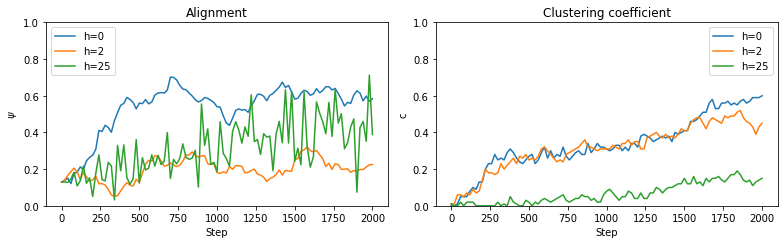

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for delay in comparison_delays:
    p, a, psi, c = results[delay]
    axes[0].plot(np.arange(len(psi)) * n_skip, psi, 
                 label=f'h={delay}')
    axes[1].plot(np.arange(len(c)) * n_skip, c, 
                 label=f'h={delay}')
axes[0].set(
    title='Alignment', 
    xlabel='Step', 
    ylabel=r'$\psi$', 
    ylim=(0, 1)
)
axes[1].set(
    title='Clustering coefficient', 
    xlabel='Step', 
    ylabel='c', 
    ylim=(0, 1)
)
for ax in axes: ax.legend()
plt.tight_layout(); plt.show()

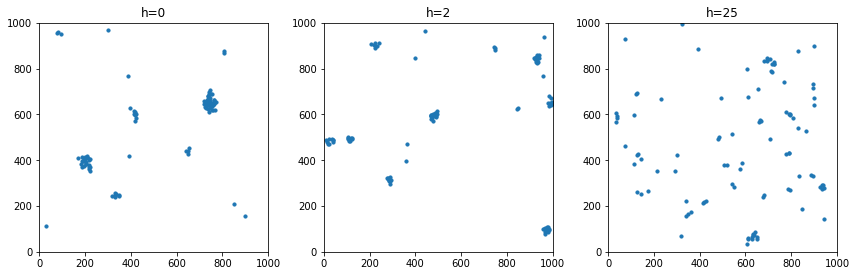

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, delay in zip(axes, comparison_delays):
    pos_final = results[delay][0]
    ax.scatter(
        pos_final[:, 0], 
        pos_final[:, 1], 
        s=10
    )
    ax.set(
        xlim=(0, box_length), 
        ylim=(0, box_length), 
        title=f'h={delay}'
    )
    ax.set_aspect('equal')
plt.tight_layout()
plt.show()

With this second protocol, the effect of positive delay on clustering looks more clear.

<a id="negative-delay"></a>
**Negative delay** in updating the orientation.

Let's now extend the simulation to negative delays $h<0$.

We do a linear extrapolation on the base of the past orientations (example, on the last $s=5$ orientations) of the current neighbours.

Note that: the predictive `h=0` and the standard Vicsek model *are not identical*.

In [19]:
n_part = 100
box_length = 1000.0
speed = 3.0
flocking_radius = 20.0 
noise = 0.1

dt = 1.0

start_pos, start_theta = vm.initial_state(n_part, box_length)

n_steps = 1000  # Then ncrease to >4-5000 
n_skip = 10

s = 5

In [20]:
future_comparison = {}
for mode, horizon in [('standard', 0), ('predicted', 2)]:
    p, a = start_pos.copy(), start_theta.copy()
    memory = [a.copy() for _ in range(s)]
    psi_series = []
    c_series = []
    for step in range(n_steps):
        if mode == 'standard':
            p, a = vm.step_metric(
                p, a, box_length, speed, 
                flocking_radius, noise, dt)
        else:
            p, a = vm.step_predictive(
                p, a, memory, horizon, box_length, speed, 
                flocking_radius, noise, dt, window=s)
        memory.append(a.copy())
        memory.pop(0)
        psi.append(vm.alignment(a))
        if step % n_skip == 0:
            psi_series.append(vm.alignment(a))
            c, _ = vm.voronoi_clustering(
                p, box_length, flocking_radius)
            c_series.append(c)
    future_comparison[mode] = (p, psi_series, c_series)

<a id="effect-negative-delay"></a>
Let's plot

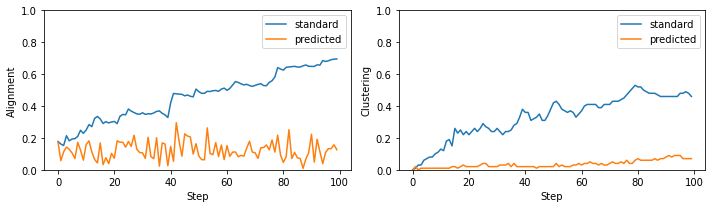

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3))

for mode, (p, psi, c) in future_comparison.items():
    axes[0].plot(psi, label=mode)
    axes[1].plot(c, label=mode)
    
for ax in axes: 
    ax.set(
        xlabel='Step', 
        ylim=(0, 1)
    )
    ax.legend()
axes[0].set_ylabel('Alignment')
axes[1].set_ylabel('Clustering')

plt.tight_layout()
plt.show()

<a id="questions"></a>
## Questions

- [Q6: Positive delay](#q6)
- [Q7: Effect of positive delay](#q7)
- [Q8: Negative Delay](#q8)
- [Q9: Effect of negative delay](#q9)

<a id="q6"></a>
### Q6: Positive delay

Refer to [positive delay](#positive-delay)

[Go back to questions](#questions)

**a.** Describe the algorithm to implement the positive delay. 

**b.** The algorithm for positive delays assumes that, when a particle $j$ has a new neighbour (let's call it $k$), immediatly $j$ has access to all the past orientation history of $k$. 
Describe how you would change the code if the particle $j$ had no access to the past history of $k$, and started observing it "from scratch", assuming the current orientation for all the past history of $k$.

**c.** The algorithm for positive delays assumes that the list of neighbours of a particle is the actual one, but the orientations are delayed in the past. Describe how you would change the code if, initially, the particle would wait before updating its orientation (according to the delayed rule) that $h+1$ steps are passed. 


<a id="q7"></a>
### Q7: Effect of positive delay

Refer to [effect of positive delay](#effect-positive-delay)

[Go back to questions](#questions)

**a.** In the print-out, comment the trend of the global alignment for the delays values represented. Is it clearly visible that the positive delay favours the global alignment? Make sure to clarify which plots you are discussing.

**b.** In the print-out, comment the trend of the clustering coefficient for the delays values represented. Is it clearly visible that the positive delay slighly hinders the clustering coefficient?

**c.** Reflect on what was presented in the notebook. How would you check the if positive delay favours or prevents global alignment with respect to the standard Vicsek model? From which density and noise conditions makes sense to start, and why?


<a id="q8"></a>
### Q8: Negative delay

Refer to [negative delay](#negative-delay)

[Go back to questions](#questions)

**a.** Describe the algorithm to implement the negative delay.
 
**b.** The algorithm for negative delays assumes that, when a particle $j$ has a new neighbour (let's call it $k$), immediately $j$ has access to all the past orientation record of $k$. 
Describe how you would change the code if the particle $j$ had no access to the past record (`memory`) of $k$, and started observing it "from scratch", assuming a *random* initial $s$ values for its orientation.

**c.** Assume `s = 2` instead of `s = 5`. Do you expect that the predicted value for a certain negative delay value `h` is different?
Why or why not?




<a id="q9"></a>
### Q9: Effect of negative delay

Refer to [effect of negative delay](#effect-negative-delay)


[Go back to questions](#questions)

**a.** In the print-out, comment the trend of the global alignment for the negative delay value represented. Is a negative delay desirable to favour the global alignment? 

**b.** In the print-out, comment the trend of the clustering coefficient for the negative delay value represented. Is a negative delay desirable to favour the clustering? 

